In [1]:
# Install required libraries (run once if they are not installed)
%pip install -q pandas numpy matplotlib seaborn scikit-learn joblib ipywidgets

Note: you may need to restart the kernel to use updated packages.


In [2]:
# Import libraries used for data handling, visualization, ML, saving and interactive widgets
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import ipywidgets as widgets

from IPython.display import display, clear_output
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42  # Keeps the train/test split reproducible
DATASET_PATH = "student-mat.csv"  # Dataset file expected beside this notebook
MODEL_PATH = "student_model.pkl"  # File used to save the trained ML pipeline

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
# Load the dataset from the notebook folder; download it if it is not present
DATASET_URL = "https://huggingface.co/datasets/DElmazi/Student_Performance/resolve/main/student-mat.csv"

if os.path.exists(DATASET_PATH):
    df = pd.read_csv(DATASET_PATH, sep=";")  # sep=';' because this CSV uses semicolons
else:
    df = pd.read_csv(DATASET_URL, sep=";")
    df.to_csv(DATASET_PATH, sep=";", index=False)  # Save a local copy for later use

print("Dataset shape:", df.shape)  # Shows rows and columns
display(df.head())  # Displays the first five records

Dataset shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [4]:
# Inspect dataset structure, missing values and numerical summaries
df.info()  # Displays column names, data types and non-null counts
display(df.isnull().sum().to_frame("missing_values"))  # Counts missing values in each column
display(df.describe())  # Summary statistics for numerical columns

<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      395 non-null    str  
 1   sex         395 non-null    str  
 2   age         395 non-null    int64
 3   address     395 non-null    str  
 4   famsize     395 non-null    str  
 5   Pstatus     395 non-null    str  
 6   Medu        395 non-null    int64
 7   Fedu        395 non-null    int64
 8   Mjob        395 non-null    str  
 9   Fjob        395 non-null    str  
 10  reason      395 non-null    str  
 11  guardian    395 non-null    str  
 12  traveltime  395 non-null    int64
 13  studytime   395 non-null    int64
 14  failures    395 non-null    int64
 15  schoolsup   395 non-null    str  
 16  famsup      395 non-null    str  
 17  paid        395 non-null    str  
 18  activities  395 non-null    str  
 19  nursery     395 non-null    str  
 20  higher      395 non-null    str  
 21  inte

,missing_values
school,0
sex,0
age,0
address,0
famsize,0
Pstatus,0
Medu,0
Fedu,0
Mjob,0
Fjob,0


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


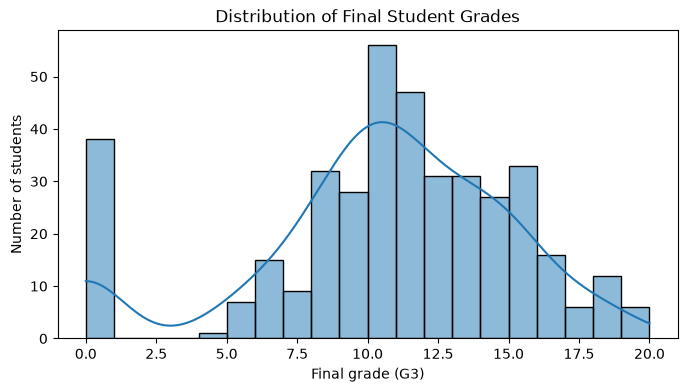

In [5]:
# Visualize the distribution of the final grade target
plt.figure(figsize=(8, 4))
sns.histplot(df["G3"], bins=20, kde=True)  # Histogram plus smoothed density curve
plt.title("Distribution of Final Student Grades")
plt.xlabel("Final grade (G3)")
plt.ylabel("Number of students")
plt.show()

In [6]:
# Separate model inputs (X) and prediction target (y)
# G3 is the final grade; G1 and G2 are removed to avoid using earlier exam marks as inputs
X = df.drop(columns=["G3", "G1", "G2"], errors="ignore")
y = df["G3"]

# Identify text/category columns and numerical columns for different preprocessing
categorical_features = X.select_dtypes(include=["str", "object", "category"]).columns.tolist()
numerical_features = X.select_dtypes(include=["number"]).columns.tolist()

print("Input features:", X.shape[1])
print("Categorical features:", categorical_features)
print("Numerical features:", numerical_features)

Input features: 30
Categorical features: ['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']
Numerical features: ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences']


In [7]:
# Split records into training data and unseen testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,  # 20% for testing; 80% for training
    random_state=RANDOM_STATE  # Same split each time
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 316
Testing records: 79


In [8]:
# Preprocess numerical and categorical columns before model training
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),  # Standardizes numerical values
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)  # Converts categories to numeric columns
    ]
)

# Build one pipeline so preprocessing is applied consistently during training and prediction
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=300,  # Number of decision trees in the forest
        random_state=RANDOM_STATE,
        min_samples_leaf=2  # Minimum samples required in each leaf
    ))
])

model.fit(X_train, y_train)  # Learns patterns from the training data
print("Model trained successfully.")

Model trained successfully.


In [9]:
# Predict grades for the test records and calculate regression metrics
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)  # Average absolute prediction error
mse = mean_squared_error(y_test, y_pred)  # Average squared prediction error
rmse = np.sqrt(mse)  # Error expressed in the target's original units
r2 = r2_score(y_test, y_pred)  # Variance explained by the model; may be negative

print("MAE :", round(mae, 3))
print("MSE :", round(mse, 3))
print("RMSE:", round(rmse, 3))
print("R2  :", round(r2, 3))

MAE : 3.041
MSE : 14.47
RMSE: 3.804
R2  : 0.294


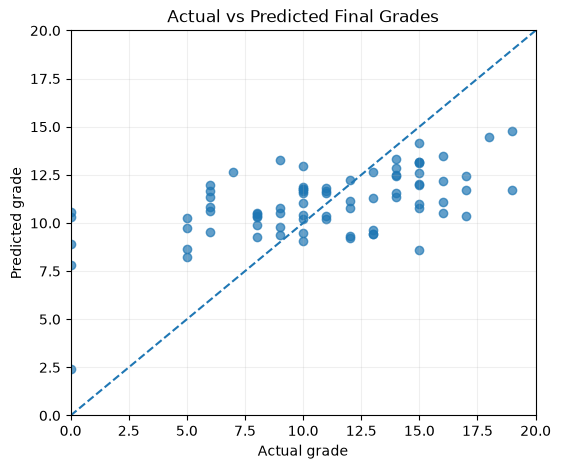

In [10]:
# Plot actual grades against predicted grades
plt.figure(figsize=(6, 5))
plt.scatter(y_test, y_pred, alpha=0.7)
plt.plot([0, 20], [0, 20], linestyle="--")  # Perfect predictions would lie on this line
plt.xlim(0, 20)
plt.ylim(0, 20)
plt.xlabel("Actual grade")
plt.ylabel("Predicted grade")
plt.title("Actual vs Predicted Final Grades")
plt.grid(alpha=0.2)
plt.show()

In [11]:
# Save the complete trained pipeline, including preprocessing steps
joblib.dump(model, MODEL_PATH)  # Creates student_model.pkl in the current folder
print("Model saved at:", os.path.abspath(MODEL_PATH))

Model saved at: C:\Users\mohan\Downloads\student_model.pkl


In [12]:
# Load the saved pipeline; useful after restarting the Jupyter kernel
model = joblib.load(MODEL_PATH)
print("Saved model loaded successfully.")

Saved model loaded successfully.


In [13]:
# Create interactive input controls based on the columns used during training
input_widgets = {}

for col in X.columns:
    if col in categorical_features:
        options = sorted(X[col].dropna().unique().tolist())
        input_widgets[col] = widgets.Dropdown(
            options=options,
            value=options[0] if options else None,
            description=col,
            style={"description_width": "initial"},
            layout=widgets.Layout(width="100%")
        )
    else:
        values = pd.to_numeric(X[col], errors="coerce").dropna()
        input_widgets[col] = widgets.IntSlider(
            value=int(round(values.median())),  # Starts at the column median
            min=int(np.floor(values.min())),
            max=int(np.ceil(values.max())),
            step=1,
            description=col,
            continuous_update=False,  # Updates after the slider is released
            style={"description_width": "initial"},
            layout=widgets.Layout(width="100%")
        )

# Arrange controls in two columns for a compact form
form_grid = widgets.GridBox(
    children=list(input_widgets.values()),
    layout=widgets.Layout(
        grid_template_columns="repeat(2, minmax(250px, 1fr))",
        grid_gap="10px 18px",
        width="100%"
    )
)

predict_button = widgets.Button(
    description="Predict Grade",
    button_style="success",  # Green success-style button
    icon="check",
    layout=widgets.Layout(width="220px", height="42px")
)

prediction_output = widgets.Output()  # Area where prediction results are displayed

display(widgets.HTML("<h3>Student Performance Prediction</h3>"))
display(form_grid)
display(predict_button)
display(prediction_output)

HTML(value='<h3>Student Performance Prediction</h3>')

GridBox(children=(Dropdown(description='school', layout=Layout(width='100%'), options=('GP', 'MS'), style=Desc…

Button(button_style='success', description='Predict Grade', icon='check', layout=Layout(height='42px', width='…

Output()

In [14]:
# Run the trained model when the Predict Grade button is clicked
def predict_from_form(_):
    with prediction_output:
        clear_output(wait=True)  # Clears the previous prediction result

        # Collect current widget values in the exact training-column order
        student_input = pd.DataFrame(
            [{col: widget.value for col, widget in input_widgets.items()}],
            columns=X.columns
        )

        predicted_grade = float(model.predict(student_input)[0])
        predicted_grade = float(np.clip(predicted_grade, 0, 20))  # Keeps display within grade range

        print("STUDENT PERFORMANCE PREDICTION")
        print("--------------------------------")
        print(f"Predicted final grade: {predicted_grade:.2f} / 20")

        # Display a simple indicative category based on the predicted grade
        if predicted_grade >= 16:
            performance = "Excellent"
        elif predicted_grade >= 12:
            performance = "Good"
        elif predicted_grade >= 10:
            performance = "Average"
        else:
            performance = "Needs Improvement"

        print("Performance category:", performance)
        print("\nEntered student values:")
        display(student_input.T.rename(columns={0: "Value"}))
        print("Note: This is a model estimate, not a guaranteed exam result.")

# Connect the button click event to the prediction function
predict_button.on_click(predict_from_form)

In [15]:
# Optional: test prediction with one existing test record
sample_student = X_test.iloc[[0]]  # Selects one row while keeping it as a DataFrame
sample_prediction = model.predict(sample_student)[0]

print("Sample predicted grade:", round(float(sample_prediction), 2), "/ 20")
print("Actual grade:", int(y_test.iloc[0]), "/ 20")

Sample predicted grade: 9.49 / 20
Actual grade: 10 / 20
